# Pixel-level disease annotation: pilot and full dataset

Annotate **only visibly disease-affected tissue**. This pilot contains six original images: 3 training, 1 validation, and 2 test images, including a healthy negative control. The original split is preserved.

The initial regions were traced from the images by the assistant. The Hispa example additionally uses pale-pixel color selection within a traced leaf region. These are **draft masks for review**, not expert ground truth or model predictions. No Grad-CAM map is used as a segmentation label. Other affected leaves or small lesions may have been missed; revise them in the editor.

Review the original, white binary mask, and red overlay below, then launch the editor to mark areas and record a 1?5 rating. Full-dataset generation was authorized by your request on 15 November 2026; see the full-dataset sections below.

All processing functions and the browser review editor are embedded in this notebook. No project-local Python or HTML helper files are needed.

## Embedded annotation implementation

Run these setup and definition cells before the workflow cells below.

In [1]:
from pathlib import Path

from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer

import hashlib

import io

import json

import threading

import cv2

import numpy as np

import pandas as pd

from PIL import Image, ImageDraw, ImageOps

from matplotlib.figure import Figure

from matplotlib.backends.backend_agg import FigureCanvasAgg

ROOT = Path.cwd().resolve()

OUT = ROOT / 'results/pixel_annotation_pilot'

COLORS = np.array([255, 45, 70], dtype=np.uint8)

FULL = ROOT / 'results/pixel_annotations_full'

In [2]:
# Editor assets are embedded here; no separate HTML file is required.
ANNOTATION_EDITOR_HTML = r'''<!doctype html>
<html lang="en"><meta charset="utf-8"><title>Disease region review</title>
<style>
body{font:15px system-ui;margin:20px;background:#f5f7f9;color:#172438}h1{font-size:23px}button,select,input,textarea{font:inherit;padding:8px;margin:4px;border:1px solid #b4becb;border-radius:5px}button{cursor:pointer;background:white}button.primary{background:#14654c;color:white}canvas{display:block;max-width:100%;max-height:72vh;object-fit:contain;cursor:crosshair;background:#ddd}main{display:flex;gap:20px;align-items:flex-start}.work{flex:1;min-width:300px}aside{width:300px;background:white;padding:15px;border-radius:8px}textarea{width:90%;height:70px}.hint{font-size:13px;color:#4b5768}#status{font-weight:600;white-space:pre-wrap}.tools{margin-bottom:8px}label{display:block;margin-top:8px}#title{overflow-wrap:anywhere}
</style>
<h1>Disease-affected tissue review</h1>
<p>Red marks affected tissue. Draft outlines need your review. Rating: 1 = unusable, 3 = needs correction, 5 = excellent.</p>
<input id="search" placeholder="Find class, split, or filename" aria-label="Find images"><select id="imageSelect"></select><button id="prev">Previous</button><button id="next">Next</button>
<main><div class="work"><div class="tools"><select id="mode"><option value="add">Add affected region</option><option value="erase">Erase false region</option></select><button id="finish">Close polygon</button><button id="undoVertex">Undo vertex</button><button id="undoRegion">Remove last region in selected mode</button><button id="clear">Clear regions</button><label style="display:inline"><input type="checkbox" id="show" checked>Show overlay</label></div><canvas id="canvas"></canvas></div>
<aside><div id="title"></div><p class="hint">Click around each affected area, then click Close polygon. Repeat for separate lesions. Remove and redraw a region to correct it. Red dots show the open outline. The mask is saved at the original image resolution.</p>
<label><input type="checkbox" id="refine">Keep pale pixels only within regions (Hispa draft)</label>
<label id="baseBox" hidden><input type="checkbox" id="useBase">Keep automatic draft mask as the base</label>
<label>Quality rating<select id="rating"><option value="">Choose</option><option>1</option><option>2</option><option>3</option><option>4</option><option>5</option></select></label>
<label>Decision<select id="decision"><option value="pending">Pending</option><option value="accept">Accept</option><option value="revise">Needs revision</option><option value="reject">Reject</option></select></label>
<label>Notes<textarea id="notes" placeholder="Missing regions, boundary corrections, unclear tissue..."></textarea></label>
<button class="primary" id="save">Save mask and rating</button><p id="status" role="status"></p><p class="hint">For a healthy image, keep an empty mask and accept it if no affected tissue is visible. Do not rate image-area coverage as disease severity.</p></aside></main>
<script>
const $=id=>document.getElementById(id), c=$('canvas'),ctx=c.getContext('2d');
let records=[],at=0,polygons=[],erasePolygons=[],vertices=[],img=new Image(),maskImage=new Image(),baseImage=new Image(),dirty=false,maskReady=false,maskDirty=false,baseReady=false,loadToken=0;
function drawMask(source){const off=document.createElement('canvas');off.width=c.width;off.height=c.height;const oc=off.getContext('2d');oc.drawImage(source,0,0,c.width,c.height);const a=oc.getImageData(0,0,c.width,c.height);for(let i=0;i<a.data.length;i+=4){let on=a.data[i]>127;a.data[i]=255;a.data[i+1]=30;a.data[i+2]=60;a.data[i+3]=on?115:0}oc.putImageData(a,0,0);ctx.drawImage(off,0,0)}
function drawPolygon(p,erase){ctx.beginPath();p.forEach(([x,y],i)=>i?ctx.lineTo(x*c.width,y*c.height):ctx.moveTo(x*c.width,y*c.height));ctx.closePath();ctx.fillStyle=erase?'rgba(30,180,255,.45)':'rgba(255,30,60,.38)';ctx.fill();ctx.strokeStyle=erase?'cyan':'#ff2038';ctx.lineWidth=2;ctx.stroke()}
function render(){if(!img.complete||!img.naturalWidth)return;ctx.clearRect(0,0,c.width,c.height);ctx.drawImage(img,0,0,c.width,c.height);if($('show').checked){
 if(maskReady&&!maskDirty){drawMask(maskImage)}
 else {if($('useBase').checked&&baseReady)drawMask(baseImage);for(const p of polygons)drawPolygon(p,false);for(const p of erasePolygons)drawPolygon(p,true)}}
 if(vertices.length){ctx.beginPath();vertices.forEach(([x,y],i)=>i?ctx.lineTo(x*c.width,y*c.height):ctx.moveTo(x*c.width,y*c.height));ctx.strokeStyle='yellow';ctx.lineWidth=2;ctx.stroke();for(const [x,y] of vertices){ctx.beginPath();ctx.arc(x*c.width,y*c.height,4,0,7);ctx.fillStyle='yellow';ctx.fill()}}}
function changed(){dirty=true;maskDirty=true;$('status').textContent='Save to refresh the exact mask. Blue regions will be erased.';render()}
async function load(n){if(dirty&&!confirm('Discard unsaved edits?')){$('imageSelect').value=at;return}const token=++loadToken;at=(n+records.length)%records.length;const r=records[at];$('imageSelect').value=at;const s=await(await fetch('/annotation/'+r.id)).json();if(token!==loadToken)return;polygons=s.polygons||[];erasePolygons=s.erase_polygons||[];vertices=[];dirty=false;maskReady=false;maskDirty=false;baseReady=false;$('refine').checked=!!s.refine_pale;$('baseBox').hidden=!s.has_base_mask;$('useBase').checked=!!s.use_base_mask;$('rating').value=s.rating||'';$('decision').value=s.decision||'pending';$('notes').value=s.notes||'';$('title').textContent=r.id+' | '+r.class+' | '+r.split+' | '+r.path;$('status').textContent='';img.onload=()=>{c.width=img.width;c.height=img.height;render()};img.src='/image/'+r.id;maskImage.onload=()=>{maskReady=true;render()};maskImage.src='/mask/'+r.id+'?t='+Date.now();if(s.has_base_mask){baseImage.onload=()=>{baseReady=true;render()};baseImage.src='/base_mask/'+r.id}}
c.addEventListener('click',e=>{const r=c.getBoundingClientRect();vertices.push([(e.clientX-r.left)/r.width,(e.clientY-r.top)/r.height]);changed()});
$('finish').onclick=()=>{if(vertices.length<3){$('status').textContent='Mark at least three vertices.';return}($('mode').value==='erase'?erasePolygons:polygons).push(vertices);vertices=[];changed()};$('undoVertex').onclick=()=>{vertices.pop();changed()};$('undoRegion').onclick=()=>{($('mode').value==='erase'?erasePolygons:polygons).pop();changed()};$('clear').onclick=()=>{if(confirm('Clear all regions for this image?')){polygons=[];erasePolygons=[];vertices=[];$('refine').checked=false;$('useBase').checked=false;changed()}};$('show').onchange=render;$('refine').onchange=changed;$('useBase').onchange=changed;
for(const id of ['rating','decision','notes'])$(id).onchange=()=>{dirty=true};
$('prev').onclick=()=>load(at-1);$('next').onclick=()=>load(at+1);$('imageSelect').onchange=e=>load(Number(e.target.value));
$('search').oninput=()=>{const q=$('search').value.toLowerCase();for(const o of $('imageSelect').options){const r=records[Number(o.value)];o.hidden=![r.id,r.class,r.split,r.path].join(' ').toLowerCase().includes(q)}};
$('save').onclick=async()=>{if(vertices.length){$('status').textContent='Close or undo the open polygon first.';return}const data={id:records[at].id,polygons,erase_polygons:erasePolygons,use_base_mask:$('useBase').checked,refine_pale:$('refine').checked,rating:Number($('rating').value),decision:$('decision').value,notes:$('notes').value};const response=await fetch('/api/save',{method:'POST',headers:{'Content-Type':'application/json'},body:JSON.stringify(data)});const result=await response.json();if(records[at].id!==data.id)return;if(!response.ok){$('status').textContent=result.error;return}dirty=false;maskDirty=false;maskReady=false;maskImage.src='/mask/'+data.id+'?t='+Date.now();$('status').textContent='Saved. Affected image area: '+result.affected_image_percent.toFixed(2)+'%.\n'+result.mask_path};
window.addEventListener('beforeunload',e=>{if(dirty){e.preventDefault();e.returnValue=''}});
(async()=>{records=await(await fetch('/api/records')).json();records.forEach((r,i)=>{const o=document.createElement('option');o.value=i;o.textContent=r.id+' — '+r.class+' / '+r.split;$('imageSelect').appendChild(o)});load(0)})();
</script></html>
'''


In [3]:
def read_image(row):
    path = ROOT / 'split_dataset' / row['split'] / row['path']
    if hashlib.sha256(path.read_bytes()).hexdigest() != row['sha256']:
        raise ValueError('Source image does not match the split manifest')
    with Image.open(path) as im:
        return ImageOps.exif_transpose(im).convert('RGB')

In [4]:
def polygon_mask(image, polygons, refine_pale=False):
    w, h = image.size
    canvas = Image.new('L', (w, h), 0)
    draw = ImageDraw.Draw(canvas)
    for polygon in polygons:
        if len(polygon) < 3:
            raise ValueError('Each region needs at least three vertices')
        points = np.asarray(polygon, dtype=float)
        if points.ndim != 2 or points.shape[1] != 2 or not np.isfinite(points).all():
            raise ValueError('Invalid polygon coordinates')
        if (points < 0).any() or (points > 1).any():
            raise ValueError('Polygon coordinates must be in [0,1]')
        draw.polygon([(round(x*(w-1)), round(y*(h-1))) for x, y in points], fill=1)
    mask = np.array(canvas, dtype=np.uint8)
    if refine_pale:
        rgb = np.array(image)
        hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
        # Pilot Hispa only: keep pale damage within the hand-drawn leaf ROI.
        pale = (hsv[:,:,1] < 110) & (rgb[:,:,0] > 130) & (rgb[:,:,1] > 120)
        mask &= pale.astype(np.uint8)
    return mask

In [5]:
def overlay(image, mask):
    rgb = np.array(image).copy()
    fg = mask.astype(bool)
    rgb[fg] = (rgb[fg]*.55 + COLORS*.45).astype(np.uint8)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(rgb, contours, -1, (255, 30, 30), max(1, round(max(image.size)/700)))
    return Image.fromarray(rgb)

In [6]:
def annotation_mask(image, spec, row):
    mask = polygon_mask(image, spec['polygons'], spec.get('refine_pale', False))
    if spec.get('use_base_mask') and row.get('draft_mask_path'):
        with Image.open(ROOT / row['draft_mask_path']) as im:
            base = np.array(im, dtype=np.uint8)
        assert base.shape == mask.shape
        mask = np.maximum(mask, base)
    if spec.get('erase_polygons'):
        erase = polygon_mask(image, spec['erase_polygons'])
        mask[erase.astype(bool)] = 0
    return mask

In [7]:
def export_record(row, spec, reviewed=False, output_root=None):
    image = read_image(row)
    mask = annotation_mask(image, spec, row)
    stem = Path(row['path']).with_suffix('.png')
    base = (output_root or OUT) / ('reviewed' if reviewed else 'draft')
    mask_path = base / 'masks' / row['split'] / stem
    overlay_path = base / 'overlays' / row['split'] / stem
    mask_path.parent.mkdir(parents=True, exist_ok=True)
    overlay_path.parent.mkdir(parents=True, exist_ok=True)
    Image.fromarray(mask).save(mask_path)
    result = overlay(image, mask)
    result.thumbnail((1000, 1000))
    result.save(overlay_path)
    return dict(id=row['id'], split=row['split'], path=row['path'], class_name=row['class'],
        source_sha256=row['sha256'], width=image.width, height=image.height,
        affected_pixels=int(mask.sum()), image_pixels=int(mask.size),
        affected_image_percent=100*float(mask.mean()),
        mask_path=str(mask_path.relative_to(ROOT)), overlay_path=str(overlay_path.relative_to(ROOT)),
        method=spec.get('method', 'reviewed polygon'), rating=spec.get('rating'),
        decision=spec.get('decision', 'pending'), notes=spec.get('notes', ''))

In [8]:
def generate_pilot():
    records = pd.read_csv(OUT / 'pilot_selection.csv').to_dict('records')
    specs = json.loads((OUT / 'draft_annotations.json').read_text())
    output = []
    fig = Figure(figsize=(13, 3.6*len(records)), layout='constrained')
    FigureCanvasAgg(fig)
    axes = fig.subplots(len(records), 3, squeeze=False)
    for axes_row, row in zip(axes, records):
        entry = export_record(row, specs[row['id']])
        output.append(entry)
        image = read_image(row)
        mask = polygon_mask(image, specs[row['id']]['polygons'], specs[row['id']].get('refine_pale', False))
        image.thumbnail((700, 700))
        shown_mask = Image.fromarray(mask*255).resize(image.size, Image.Resampling.NEAREST)
        shown_overlay = overlay(image, np.array(shown_mask)//255)
        for ax, im, title in zip(axes_row, [image, shown_mask, shown_overlay],
                [f"{row['id']} | {row['class']}\n{row['split']}", 'Disease mask: white = affected',
                 f"Draft overlay | {entry['affected_image_percent']:.2f}% of image"]):
            ax.imshow(im, cmap='gray', vmin=0, vmax=255)
            ax.set_title(title, fontsize=10)
            ax.axis('off')
    fig.suptitle('Disease-region annotation pilot — DRAFT / awaiting review', fontsize=17)
    fig.savefig(OUT / 'pilot_annotation_contact_sheet.png', dpi=130)
    pd.DataFrame(output).to_csv(OUT / 'draft_manifest.csv', index=False)
    (OUT / 'label_schema.json').write_text(json.dumps({
        'mask_values': {'0': 'unmarked (background or apparently unaffected tissue)',
                        '1': 'visibly disease-affected tissue'},
        'coordinates': 'EXIF-transposed full-resolution source image',
        'scope': 'visible symptomatic tissue; include contiguous discoloration halo in draft',
        'status': 'draft proposals; not expert ground truth',
        'measurement': 'affected_image_percent uses image area, not leaf area; not disease severity',
        'healthy_control': 'empty mask; not a failed annotation',
        'limitations': 'appearance cannot establish lesion cause; missed regions and boundaries require review'
    }, indent=2))
    return pd.DataFrame(output)

In [9]:
def review_table(output_root=None):
    rows = []
    for path in sorted(((output_root or OUT) / 'reviews').glob('*.json')):
        spec = json.loads(path.read_text())
        rows.append(dict(id=path.stem, rating=spec.get('rating'), decision=spec.get('decision'),
                         notes=spec.get('notes', '')))
    return pd.DataFrame(rows, columns=['id', 'rating', 'decision', 'notes'])

In [10]:
def prepare_full_dataset_queue(confirmed=False):
    """Stage the full review queue when the user explicitly authorizes full annotation."""
    manifest = pd.read_csv(ROOT / 'split_dataset/manifest.csv')
    if not confirmed:
        return manifest.groupby('split').size().rename('images_to_annotate').to_frame()
    # Queue every original exactly once, retaining the existing train/validation/test split.
    manifest.insert(0, 'id', [f'full_{i:05d}' for i in range(len(manifest))])
    manifest['annotation_status'] = 'pending'
    auto_path = FULL / 'original_masks_manifest.csv'
    if auto_path.exists():
        auto = pd.read_csv(auto_path).rename(columns={'mask_path': 'draft_mask_path'})
        manifest = manifest.merge(auto[['id','draft_mask_path','review_flags']], on='id', how='left', validate='one_to_one')
        flags = manifest['review_flags'].fillna('')
        manifest['review_priority'] = (
            flags.str.contains('empty_nonhealthy_mask|weak_plant_support').astype(int)*3
            + flags.str.contains('large_marked_area').astype(int)*2
            + flags.str.contains('complex_vegetation_background|diffuse_yellowing').astype(int))
        manifest = manifest.sort_values(['review_priority','id'], ascending=[False,True])
    path = OUT / 'full_dataset_queue.csv'
    manifest.to_csv(path, index=False)
    return path

In [11]:
def start_review_server(queue_path=None, port=0):
    """Start a loopback-only editor. Only records in the selected queue are accessible."""
    queue_path = Path(queue_path) if queue_path else OUT / 'pilot_selection.csv'
    if queue_path.name != 'pilot_selection.csv':
        if queue_path.resolve() != (OUT / 'full_dataset_queue.csv').resolve():
            raise ValueError('Use the gated full-dataset queue or the pilot selection')
        prepare_full_dataset_queue(confirmed=True)
    records = pd.read_csv(queue_path).to_dict('records')
    lookup = {r['id']: r for r in records}
    review_out = OUT if queue_path.name == 'pilot_selection.csv' else FULL
    drafts = json.loads((OUT / 'draft_annotations.json').read_text())
    (review_out / 'reviews').mkdir(parents=True, exist_ok=True)
    lock = threading.Lock()

    def get_spec(key):
        path = review_out / 'reviews' / (key+'.json')
        if path.exists():
            return json.loads(path.read_text())
        return drafts.get(key, {'polygons': [], 'erase_polygons': [],
            'use_base_mask': bool(lookup[key].get('draft_mask_path')),
            'has_base_mask': bool(lookup[key].get('draft_mask_path')),
            'rating': None, 'decision': 'pending', 'notes': '', 'refine_pale': False})

    class Handler(BaseHTTPRequestHandler):
        def log_message(self, *args):
            pass

        def respond(self, data, content_type='application/json', status=200):
            if content_type == 'application/json':
                data = json.dumps(data).encode()
            elif isinstance(data, str):
                data = data.encode()
            self.send_response(status)
            self.send_header('Content-Type', content_type)
            self.send_header('Cache-Control', 'no-store')
            self.send_header('Content-Length', str(len(data)))
            self.end_headers()
            self.wfile.write(data)

        def do_GET(self):
            route = self.path.split('?')[0]
            if route == '/':
                return self.respond(ANNOTATION_EDITOR_HTML, 'text/html; charset=utf-8')
            if route == '/api/records':
                return self.respond([{k: r[k] for k in ['id','class','split','path']} for r in records])
            parts = route.strip('/').split('/')
            if len(parts) != 2 or parts[1] not in lookup:
                return self.respond({'error': 'Not found'}, status=404)
            kind, key = parts
            if kind == 'image':
                im = read_image(lookup[key]); im.thumbnail((1200, 1200))
                buf = io.BytesIO(); im.save(buf, format='PNG')
                return self.respond(buf.getvalue(), 'image/png')
            if kind == 'annotation':
                spec = get_spec(key)
                spec['has_base_mask'] = bool(lookup[key].get('draft_mask_path'))
                return self.respond(spec)
            if kind == 'mask':
                spec = get_spec(key)
                im = read_image(lookup[key])
                mask = annotation_mask(im, spec, lookup[key])
                preview = Image.fromarray(mask*255); preview.thumbnail((1200,1200), Image.Resampling.NEAREST)
                buf=io.BytesIO();preview.save(buf,format='PNG')
                return self.respond(buf.getvalue(),'image/png')
            if kind == 'base_mask' and lookup[key].get('draft_mask_path'):
                with Image.open(ROOT/lookup[key]['draft_mask_path']) as im:
                    preview=Image.fromarray(np.array(im)*255)
                preview.thumbnail((1200,1200),Image.Resampling.NEAREST)
                buf=io.BytesIO();preview.save(buf,format='PNG')
                return self.respond(buf.getvalue(),'image/png')
            return self.respond({'error': 'Not found'}, status=404)

        def do_POST(self):
            origin = self.headers.get('Origin')
            if origin and origin != 'http://' + self.headers.get('Host', ''):
                return self.respond({'error': 'Origin mismatch'}, status=403)
            if self.path != '/api/save':
                return self.respond({'error': 'Not found'}, status=404)
            try:
                length = int(self.headers.get('Content-Length', 0))
                if not 0 < length < 2_000_000:
                    raise ValueError('Invalid request size')
                data = json.loads(self.rfile.read(length))
                key = data.pop('id')
                if key not in lookup:
                    raise ValueError('Unknown image')
                if data.get('rating') not in range(1,6):
                    raise ValueError('Select a rating from 1 to 5')
                if data.get('decision') not in ['accept','revise','reject']:
                    raise ValueError('Select a review decision')
                if not isinstance(data.get('polygons'), list) or not isinstance(data.get('notes',''),str):
                    raise ValueError('Invalid annotation')
                data['method'] = 'user-reviewed polygons' + (' with pale-tissue refinement' if data.get('refine_pale') else '')
                if data.get('use_base_mask'):
                    data['method'] = 'user-reviewed automatic mask with added/erased polygons'
                data['source_sha256'] = lookup[key]['sha256']
                with lock:
                    result = export_record(lookup[key], data, reviewed=True, output_root=review_out)
                    path = review_out / 'reviews' / (key+'.json')
                    path.write_text(json.dumps(data, indent=2), encoding='utf-8')
                    review_table(review_out).to_csv(review_out / 'review_ratings.csv', index=False)
                    manifest_path = review_out / 'reviewed_manifest.csv'
                    previous = pd.read_csv(manifest_path) if manifest_path.exists() else pd.DataFrame()
                    if not previous.empty:
                        previous = previous[previous['id'] != key]
                    pd.concat([previous, pd.DataFrame([result])], ignore_index=True).to_csv(manifest_path, index=False)
                return self.respond(result)
            except (ValueError, KeyError, TypeError) as exc:
                return self.respond({'error': str(exc)}, status=400)

    server = ThreadingHTTPServer(('127.0.0.1', port), Handler)
    thread = threading.Thread(target=server.serve_forever, daemon=True)
    thread.start()
    return server, f'http://127.0.0.1:{server.server_port}/'

## Full-dataset annotation functions

These functions use separate full-output paths while the pilot helpers keep their pilot paths.

In [12]:
PILOT = OUT
from pathlib import Path

from concurrent.futures import ThreadPoolExecutor

import hashlib

import json

import time

import cv2

import numpy as np

import pandas as pd

from PIL import Image, ImageOps

FULL_OUT = ROOT / 'results/pixel_annotations_full'

VERSION = 'color_proposals_v2'

PARAMETERS = dict(version=VERSION, support_max_side=1024, support_close=17,
                  support_dilation=11, min_component_pixels=6,
                  source_orientation='EXIF-transposed', labels={'0':'unmarked','1':'candidate disease tissue'})

In [13]:
def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

In [14]:
def atomic_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix('.tmp')
    temp.write_text(json.dumps(value, indent=2), encoding='utf-8')
    temp.replace(path)

In [15]:
def save_mask(mask, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix('.tmp')
    Image.fromarray(mask.astype(np.uint8)).save(temp, format='PNG')
    temp.replace(path)

In [16]:
def propose_mask(image, class_name):
    """Color cues inside a plant-color support, with native-resolution classification.

    The support is only a background filter, not a reliable leaf segmentation.
    Gray backgrounds and soil can still be mistaken for symptoms, and low-contrast
    disease can be missed. All outputs therefore remain pending human review.
    """
    w, h = image.size
    if class_name == 'Healthy Rice Leaf':
        return np.zeros((h,w), np.uint8), ['healthy_label_empty_mask']
    small = image.copy()
    small.thumbnail((1024,1024))
    rgb = np.array(small)
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    hue, saturation, value = cv2.split(hsv)
    green = ((hue >= 32) & (hue <= 95) & (saturation >= 40) & (value >= 30))
    yellow = ((hue >= 19) & (hue < 36) & (saturation >= 65) & (value >= 50))
    plant = (green | yellow).astype(np.uint8)
    closed = cv2.morphologyEx(plant, cv2.MORPH_CLOSE,
                            cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(17,17)))
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    support = np.zeros_like(closed)
    cv2.drawContours(support, contours, -1, 1, cv2.FILLED)
    support = cv2.dilate(support, cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(11,11)))
    flags = ['automatic_color_proposal_requires_review']
    if plant.mean() > .35:
        flags.append('complex_vegetation_background')
    if plant.mean() < .01:
        flags.append('weak_plant_support')
    if class_name == 'Rice Turgro':
        flags.append('diffuse_yellowing_not_specific_to_disease')
    support = cv2.resize(support, (w,h), interpolation=cv2.INTER_NEAREST).astype(bool)
    rgb = np.array(image)
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    hue, saturation, value = cv2.split(hsv)
    red, green_channel, blue = [rgb[:,:,i].astype(np.int16) for i in range(3)]
    # Necrosis / yellowing and pale feeding scars, rather than green tissue.
    brown_yellow = ((hue >= 3) & (hue <= 35) & (saturation >= 55) & (value >= 35)
                    & (red*100 >= green_channel*91) & (red > blue+12))
    pale = ((saturation < 105) & (value >= 125) & (red > blue+7)
            & (green_channel > blue+4) & (red*100 >= green_channel*90))
    if class_name == 'Rice Hispa':
        candidates = pale & (saturation < 95) & (value >= 150)
    elif class_name in ['Brown Spot','Narrow Brown Leaf Spot']:
        candidates = ((brown_yellow & (hue <= 23) & (red*100 >= green_channel*111) & (value <= 210))
                      | (pale & (red*100 >= green_channel*104) & (value <= 210)))
    else:
        candidates = brown_yellow | pale
    mask = (support & candidates).astype(np.uint8)
    count, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    keep = stats[:, cv2.CC_STAT_AREA] >= max(6, round(w*h/2_000_000))
    keep[0] = False
    mask = keep[labels].astype(np.uint8)
    # When a long symptomatic leaf provides a clear axis, reject distant background
    # candidates. This is a heuristic, so images with additional leaves remain flagged.
    if mask.any():
        anchor = 1 + int(stats[1:,cv2.CC_STAT_AREA].argmax())
        anchor_small = cv2.resize((labels == anchor).astype(np.uint8), small.size, interpolation=cv2.INTER_NEAREST)
        points = cv2.findNonZero(anchor_small)
        if points is not None and len(points) >= 3:
            rect = cv2.minAreaRect(points)
            (cx,cy),(rw,rh),angle=rect
            major,minor=max(rw,rh),min(rw,rh)
            if major >= .25*max(small.size) and major >= 2*max(minor,1):
                if rh > rw: angle+=90
                radians=np.deg2rad(angle)
                direction=np.array([np.cos(radians),np.sin(radians)])
                center=np.array([cx,cy]); extent=2*max(small.size)
                ends=[tuple(np.rint(center+t*extent*direction).astype(int)) for t in [-1,1]]
                corridor=np.zeros(anchor_small.shape,np.uint8)
                cv2.line(corridor,ends[0],ends[1],1,max(3,round(minor+.07*max(small.size))))
                mask &= cv2.resize(corridor,(w,h),interpolation=cv2.INTER_NEAREST)
                flags.append('dominant_leaf_axis_filter_may_miss_other_leaves')
    if not mask.any():
        flags.append('empty_nonhealthy_mask')
    elif mask.mean() > .40:
        flags.append('large_marked_area')
    return mask, flags

In [17]:
def mask_views(mask):
    image = ImageOps.fit(Image.fromarray(mask), (256,256), method=Image.Resampling.NEAREST)
    pad = 64
    padded = Image.fromarray(np.pad(np.array(image), ((pad,pad),(pad,pad)), mode='reflect'))
    def rotate(angle):
        return padded.rotate(angle, resample=Image.Resampling.NEAREST).crop((pad,pad,pad+256,pad+256))
    return [ImageOps.mirror(image), rotate(-15), rotate(15), image]

In [18]:
def load_overrides():
    selection = pd.read_csv(PILOT/'pilot_selection.csv')
    specs = json.loads((PILOT/'draft_annotations.json').read_text())
    overrides = {}
    for row in selection.to_dict('records'):
        review = PILOT/'reviews'/(row['id']+'.json')
        spec = json.loads(review.read_text()) if review.exists() else specs[row['id']]
        overrides[(row['split'],row['path'])] = spec
    return overrides

In [19]:
def process_original(row, overrides, force=False, cached_records=None):
    key = row['id']
    spec = overrides.get((row['split'],row['path']))
    settings_hash = hashlib.sha256(json.dumps(dict(parameters=PARAMETERS, override=spec),sort_keys=True).encode()).hexdigest()
    if cached_records and key in cached_records and not force:
        cached = cached_records[key]
        mask_path = ROOT/cached['mask_path']
        if (cached.get('settings_sha256') == settings_hash and cached['source_sha256'] == row['sha256']
                and mask_path.exists() and digest(mask_path) == cached['mask_sha256']
                and (ROOT/cached['overlay_path']).exists()):
            return cached
    source = ROOT/'split_dataset'/row['split']/row['path']
    assert digest(source) == row['sha256'], f'Source hash mismatch: {source}'
    with Image.open(source) as im:
        image = ImageOps.exif_transpose(im).convert('RGB')
    if spec:
        mask = polygon_mask(image, spec['polygons'], spec.get('refine_pale',False))
        flags = ['retained_pilot_regions_require_review']
        method = spec.get('method','pilot polygon')
    else:
        mask, flags = propose_mask(image,row['class'])
        method = VERSION if row['class'] != 'Healthy Rice Leaf' else 'healthy_image_label_empty_mask'
    mask_path = FULL_OUT/'masks'/row['split']/Path(row['path']).with_suffix('.png')
    preview_path = FULL_OUT/'overlays'/row['split']/Path(row['path']).with_suffix('.jpg')
    save_mask(mask,mask_path)
    preview_path.parent.mkdir(parents=True,exist_ok=True)
    small = image.copy();small.thumbnail((640,640))
    preview_mask = cv2.resize(mask,small.size,interpolation=cv2.INTER_NEAREST)
    overlay(small,preview_mask).save(preview_path,quality=88)
    record = dict(id=key, split=row['split'], path=row['path'], class_name=row['class'],
        source_sha256=row['sha256'], width=image.width, height=image.height,
        mask_path=mask_path.relative_to(ROOT).as_posix(), overlay_path=preview_path.relative_to(ROOT).as_posix(),
        mask_sha256=digest(mask_path), affected_pixels=int(mask.sum()), image_pixels=int(mask.size),
        affected_image_percent=float(mask.mean()*100), method=method,
        annotation_status='draft_pending_review', is_ground_truth=False, review_flags=';'.join(flags),
        settings_sha256=settings_hash, rating=None, decision='pending')
    return record

In [20]:
def augment_original(row, augmented_lookup):
    mask = np.array(Image.open(ROOT/row['mask_path']))
    views = mask_views(mask)
    results = []
    for aug in augmented_lookup[row['path']]:
        assert aug['source_sha256'] == row['source_sha256']
        image_path = ROOT/'augmented_train'/aug['path']
        with Image.open(image_path) as im:
            assert im.size == (256,256)
        target = FULL_OUT/'masks'/'augmented_train'/aug['path']
        view = np.array(views[int(aug['view'])-1],dtype=np.uint8)
        save_mask(view,target)
        results.append(dict(path=aug['path'], class_name=aug['class'], source_path=row['path'],
            source_sha256=aug['source_sha256'], source_mask_sha256=row['mask_sha256'],
            view=int(aug['view']), mask_path=target.relative_to(ROOT).as_posix(), mask_sha256=digest(target),
            width=256,height=256, affected_pixels=int(view.sum()), annotation_status='draft_pending_review',
            is_ground_truth=False, split='train', method='source_mask_with_matching_geometric_transform'))
    return results

In [21]:
def create_contact_sheets(frame):
    from matplotlib.figure import Figure
    from matplotlib.backends.backend_agg import FigureCanvasAgg
    (FULL_OUT/'contact_sheets').mkdir(exist_ok=True)
    for split in ['train','validation','test']:
        sample = frame[frame.split==split].groupby('class_name',sort=True).sample(1,random_state=42)
        fig = Figure(figsize=(12,3*len(sample)),layout='constrained');FigureCanvasAgg(fig)
        axes=fig.subplots(len(sample),3,squeeze=False)
        for axs,row in zip(axes,sample.to_dict('records')):
            with Image.open(ROOT/'split_dataset'/row['split']/row['path']) as im:
                image=ImageOps.exif_transpose(im).convert('RGB');image.thumbnail((600,600))
            with Image.open(ROOT/row['mask_path']) as im:
                mask=im.resize(image.size,Image.Resampling.NEAREST)
            for ax,im,title in zip(axs,[image,Image.fromarray(np.array(mask)*255),overlay(image,np.array(mask))],
                    [row['class_name']+' / '+split,'White = candidate affected tissue',f"Draft overlay / {row['affected_image_percent']:.1f}% of image"]):
                ax.imshow(im,cmap='gray',vmin=0,vmax=255);ax.set_title(title,fontsize=9);ax.axis('off')
        fig.suptitle('AUTOMATIC DRAFTS - pending human review',fontsize=16)
        fig.savefig(FULL_OUT/'contact_sheets'/(split+'_examples.jpg'),dpi=110)

In [22]:
def verify_exports(frame, augmented, workers=4):
    def verify(row):
        with Image.open(ROOT/row['mask_path']) as im:
            mask=np.array(im)
        assert mask.shape==(row['height'],row['width'])
        assert set(np.unique(mask)).issubset({0,1})
        assert int(mask.sum())==row['affected_pixels']
        assert digest(ROOT/row['mask_path'])==row['mask_sha256']
    rows=frame.to_dict('records')+augmented.to_dict('records')
    with ThreadPoolExecutor(max_workers=workers) as pool:
        list(pool.map(verify,rows))
    assert frame.path.is_unique and frame.source_sha256.is_unique
    expected=pd.read_csv(ROOT/'split_dataset/manifest.csv')
    assert len(frame)==len(expected)
    assert set(zip(frame.split,frame.path))==set(zip(expected.split,expected.path))
    assert set(augmented.path)==set(pd.read_csv(ROOT/'augmented_train/manifest.csv').path)
    assert augmented.groupby('source_path').size().eq(4).all()
    assert frame.loc[frame.class_name=='Healthy Rice Leaf','affected_pixels'].eq(0).all()
    assert not frame.is_ground_truth.any() and not augmented.is_ground_truth.any()
    return dict(original_masks=len(frame),augmented_masks=len(augmented),
        binary_labels=True,dimensions=True,pixel_counts=True,mask_hashes=True,
        complete_split_coverage=True,healthy_masks_empty=True,status='passed')

In [23]:
def run_full_annotation(workers=4,force=False,limit=None):
    cv2.setNumThreads(1)
    FULL_OUT.mkdir(parents=True,exist_ok=True)
    manifest=pd.read_csv(ROOT/'split_dataset/manifest.csv')
    manifest.insert(0,'id',[f'full_{i:05d}' for i in range(len(manifest))])
    if limit: manifest=manifest.groupby(['split','class'],sort=False).head(1).head(limit)
    overrides=load_overrides()
    # Reuse consolidated manifests rather than thousands of per-image JSON files.
    cached_records={}
    for cache_name in ['original_masks_manifest.csv','manifest_in_progress.csv','preview_manifest.csv']:
        cache_path=FULL_OUT/cache_name
        if cache_path.exists():
            for record in pd.read_csv(cache_path).to_dict('records'):
                cached_records[record['id']]=record
    config=dict(parameters=PARAMETERS,authorization='User requested full-dataset annotation on 2026-11-15',
        split_manifest_sha256=digest(ROOT/'split_dataset/manifest.csv'),
        augmentation_manifest_sha256=digest(ROOT/'augmented_train/manifest.csv'),
        mask_schema={'0':'unmarked / apparently unaffected / background','1':'candidate visibly affected tissue'},
        is_ground_truth=False,learned_model=False,review_status='pending',
        limitations=['Color does not establish disease cause. Background, age, glare and shadows can cause false labels.',
          'Pilot acceptance does not establish quality on all classes or backgrounds.',
          'All masks need image-specific human review before use as reference segmentation labels.',
          'Affected-image percentage is not affected-leaf percentage or disease severity.'])
    atomic_json(FULL_OUT/'config.json',config)
    started=time.perf_counter();results=[]
    with ThreadPoolExecutor(max_workers=workers) as pool:
        for i,record in enumerate(pool.map(lambda r:process_original(r,overrides,force,cached_records),manifest.to_dict('records')),1):
            results.append(record)
            if i%100==0 or i==len(manifest):
                pd.DataFrame(results).to_csv(FULL_OUT/'manifest_in_progress.csv',index=False)
                print(f'Originals {i}/{len(manifest)} | {(time.perf_counter()-started)/60:.1f} min',flush=True)
    frame=pd.DataFrame(results)
    if limit:
        frame.to_csv(FULL_OUT/'preview_manifest.csv',index=False)
        create_contact_sheets(frame)
        return
    frame.to_csv(FULL_OUT/'original_masks_manifest.csv',index=False)
    aug=pd.read_csv(ROOT/'augmented_train/manifest.csv')
    lookup={k:g.to_dict('records') for k,g in aug.groupby('source_path')}
    train=frame[frame.split=='train'].to_dict('records');augmented=[]
    with ThreadPoolExecutor(max_workers=workers) as pool:
        for i,group in enumerate(pool.map(lambda r:augment_original(r,lookup),train),1):
            augmented.extend(group)
            if i%200==0 or i==len(train):
                print(f'Augmented masks {len(augmented)}/{len(aug)}',flush=True)
    augmented=pd.DataFrame(augmented)
    augmented.to_csv(FULL_OUT/'augmented_masks_manifest.csv',index=False)
    create_contact_sheets(frame)
    validation=verify_exports(frame,augmented,workers)
    atomic_json(FULL_OUT/'validation.json',validation)
    frame.groupby(['split','class_name']).agg(images=('id','size'),
        empty_masks=('affected_pixels',lambda x:int((x==0).sum())),
        mean_affected_image_percent=('affected_image_percent','mean')).to_csv(FULL_OUT/'class_split_summary.csv')
    summary=dict(original_images=len(frame),original_split_counts=frame.split.value_counts().to_dict(),
        augmented_training_masks=len(augmented),total_masks=len(frame)+len(augmented),
        all_pending_review=True,ground_truth_claimed=False,
        automatic_color_masks=int((frame.method==VERSION).sum()),
        retained_pilot_masks=int(frame.method.str.contains('polygon').sum()),
        nonhealthy_empty_masks=int(((frame.class_name!='Healthy Rice Leaf')&(frame.affected_pixels==0)).sum()),
        validation=validation,elapsed_minutes=(time.perf_counter()-started)/60)
    atomic_json(FULL_OUT/'summary.json',summary)
    print(json.dumps(summary,indent=2),flush=True)

In [24]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display, Image as DisplayImage, IFrame
print('Project:', ROOT)
selection = pd.read_csv(OUT / 'pilot_selection.csv')
display(selection[['id', 'class', 'split', 'path']])

Project: C:\paras\Final-Year-Project\Final-Year-Project


,id,class,split,path
0,pilot_01,Bacterial Leaf Blight,train,Bacterial Leaf Blight/Bacterial_leaf_Blight (...
1,pilot_02,Brown Spot,validation,Brown Spot/bs_wb_8.jpg
2,pilot_03,Healthy Rice Leaf,test,Healthy Rice Leaf/bd5_f1f69bff2cd3290c.jpg
3,pilot_04,Leaf Blast,train,Leaf Blast/Leaf_blast (115).jpg
4,pilot_05,Rice Hispa,train,Rice Hispa/Rice_hispa (14).jpg
5,pilot_06,Sheath Blight,test,Sheath Blight/Sheath_blight (235).jpg


## Labels and annotation policy

- Mask **1** = visibly affected tissue; **0** = unmarked background or apparently unaffected tissue. The saved PNG contains integer labels 0/1, not overlay colors. The white visualization scales label 1 to 255.
- Trace visible brown/necrotic/pale lesions and contiguous discolored margins. Whether faint yellow margins belong in the mask must be confirmed in this review. Do not infer hidden disease from the image-level class name.
- Keep separate regions for separate lesions. A healthy control should have an empty mask. For unclear symptoms, choose **Needs revision** and describe the uncertainty instead of accepting it.
- The masks match the **EXIF-transposed original image dimensions**, without a training center crop. Preview images are smaller for display only. Load training images using the same EXIF correction.
- Area percentages below use **total image area**, not leaf area; they are not disease-severity estimates.
- All six are pending review. The pilot does not cover all nine classes or establish accuracy on the dataset.

,id,class_name,split,affected_pixels,affected_image_percent,decision
0,pilot_01,Bacterial Leaf Blight,train,148693,7.744427,pending
1,pilot_02,Brown Spot,validation,98429,1.212132,pending
2,pilot_03,Healthy Rice Leaf,test,0,0.000000,pending
3,pilot_04,Leaf Blast,train,89199,4.645781,pending
4,pilot_05,Rice Hispa,train,54240,2.825000,pending
5,pilot_06,Sheath Blight,test,80090,28.998678,pending


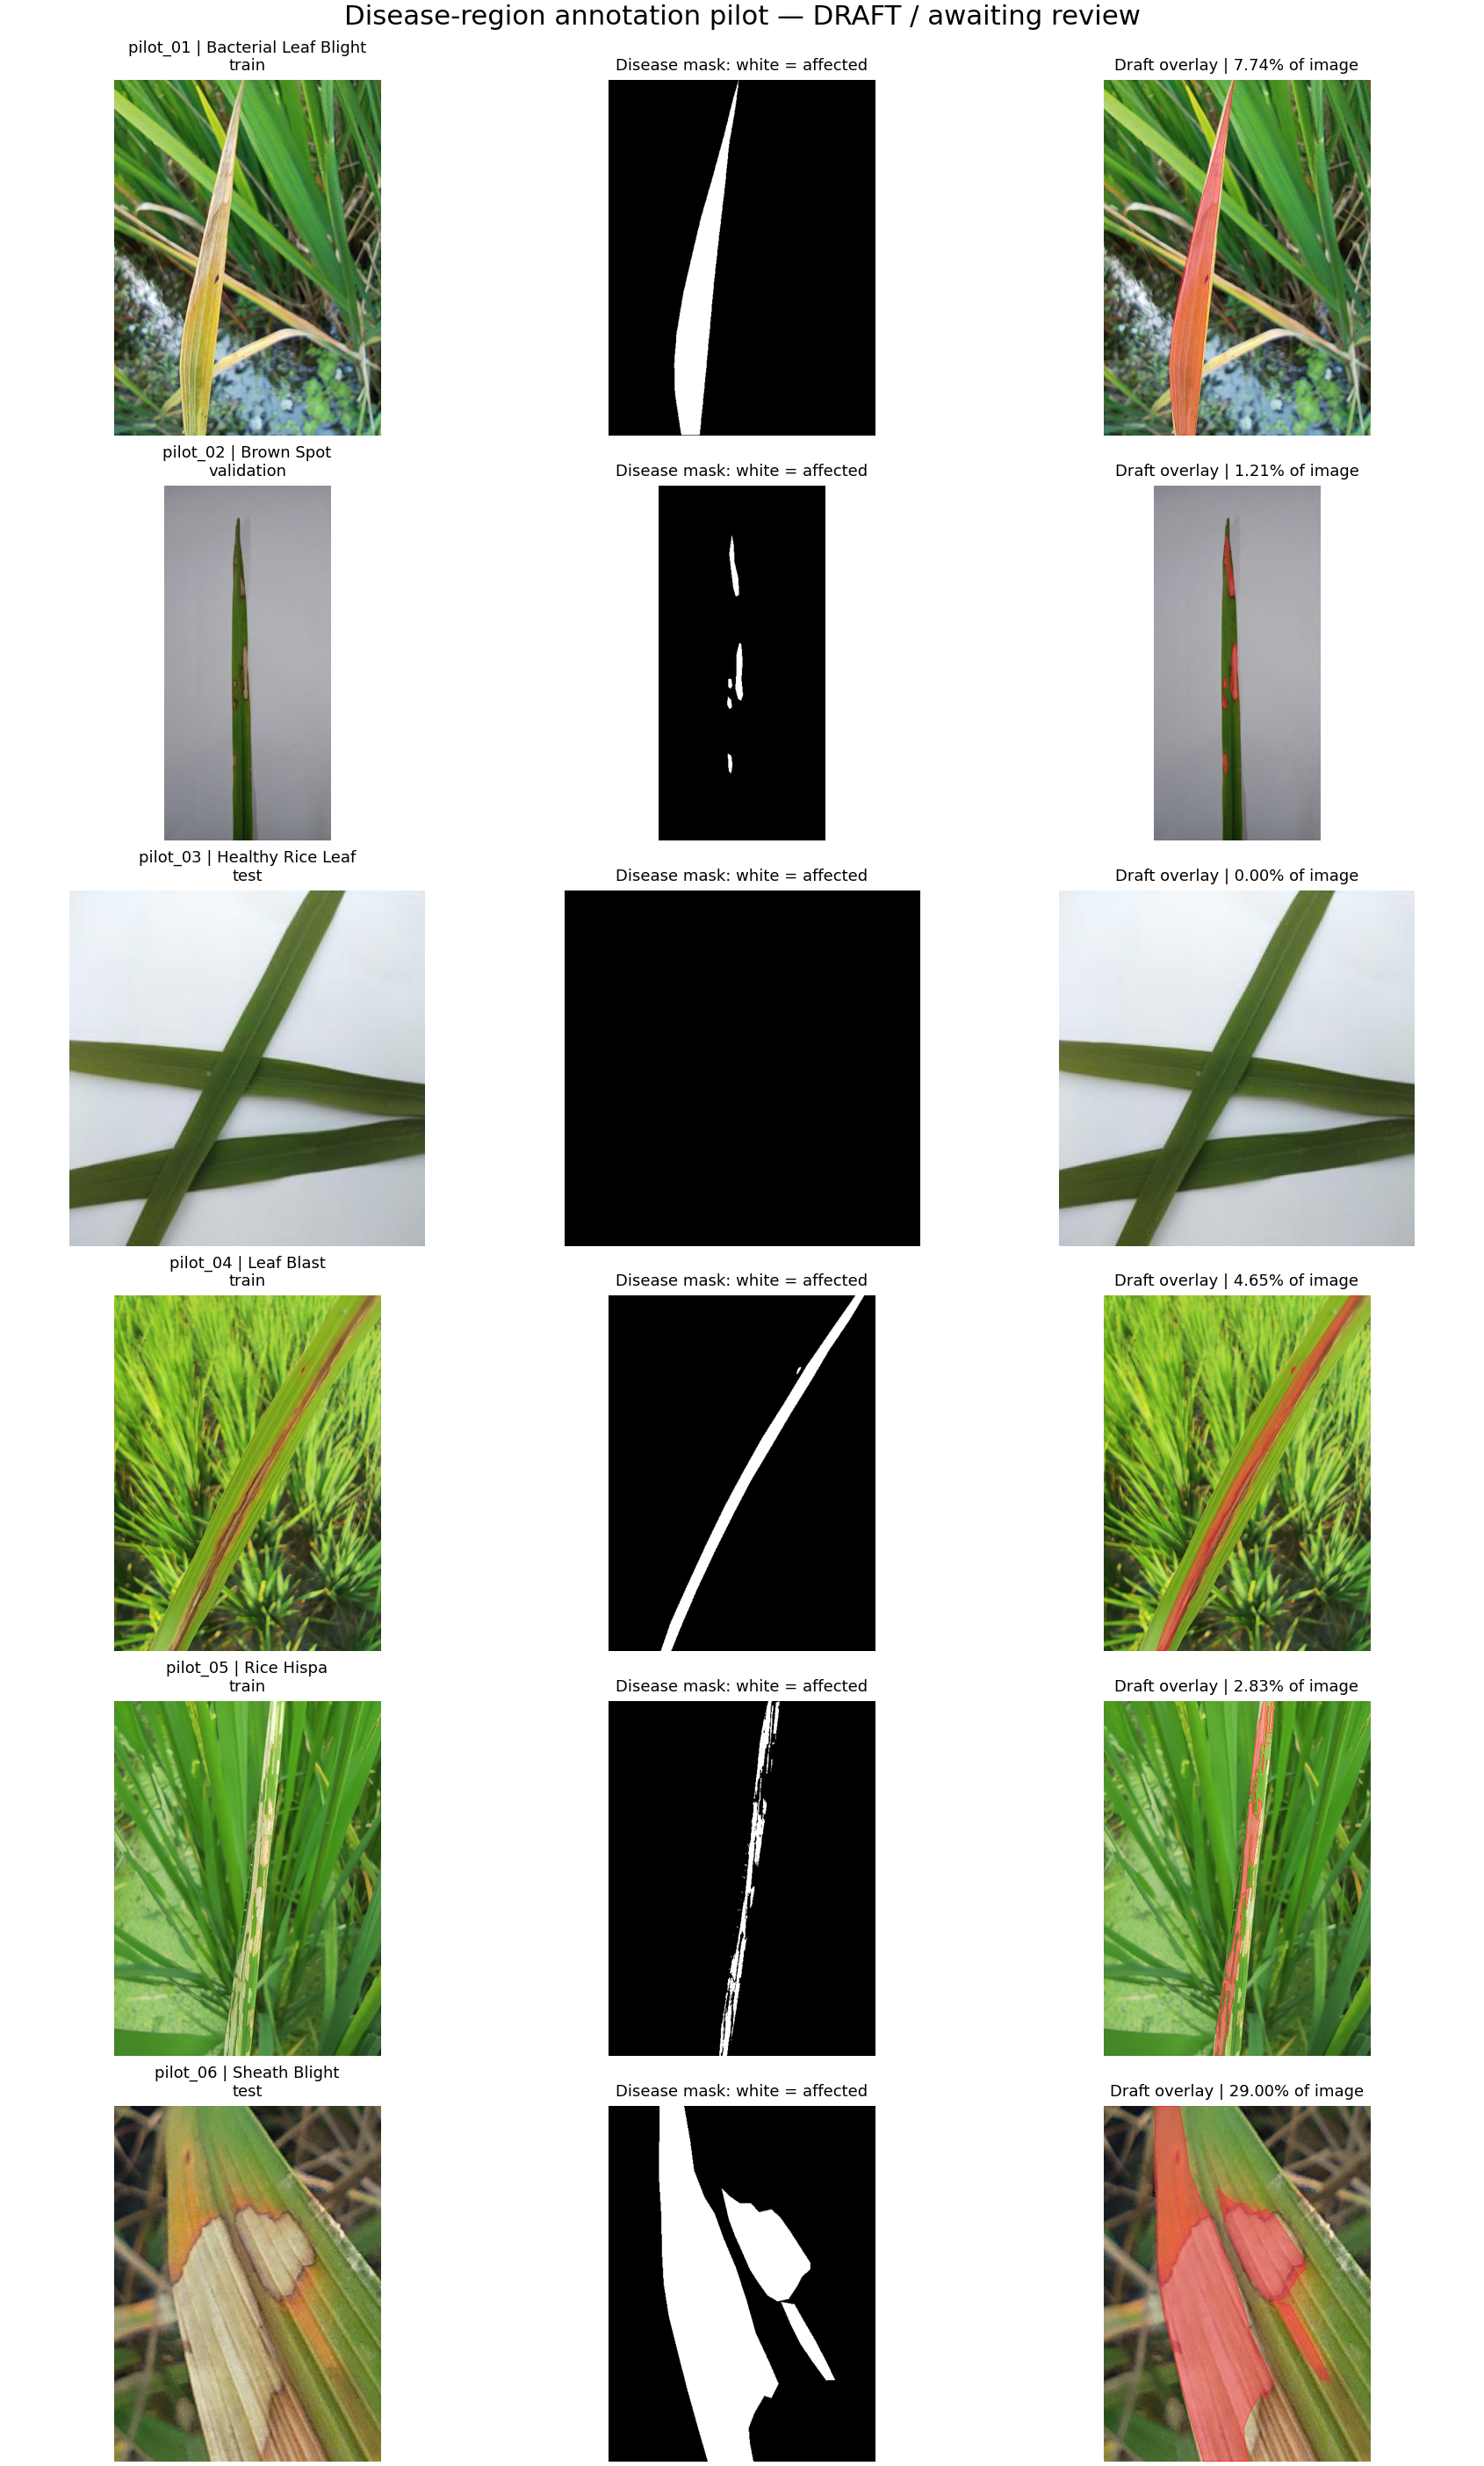

In [25]:
# Rebuilds only the draft exports; your reviewed masks and ratings are kept separately.
draft = generate_pilot()
display(draft[['id', 'class_name', 'split', 'affected_pixels', 'affected_image_percent', 'decision']])
display(DisplayImage(filename=str(OUT / 'pilot_annotation_contact_sheet.png')))

## Mark areas and rate the masks

Run the next cell to open the local editor. Click around each affected area, then **Close polygon**. Repeat for additional lesions. Remove the last region or clear and redraw to correct boundaries. Use the overlay toggle to compare with the original.

For Hispa, the pale-pixel refinement checkbox preserves the thin light streaks inside the traced region; after editing, save to refresh that exact mask preview. Turn it off to use the full polygon area.

Choose a quality rating (**1 unusable, 2 poor, 3 needs correction, 4 good, 5 excellent**), a decision, and optional notes, then **Save mask and rating**. Saving exports a full-resolution mask, overlay, polygons, and review record. An empty healthy mask can be accepted. Reviews are saved under `results/pixel_annotation_pilot/reviewed/` and `reviews/`.

The editor is available only while this kernel/server is running. If the inline frame is blocked, open the printed localhost link in your browser. All server code is embedded above; no external script is needed.

In [ ]:
# Run this cell when you are ready to review. Rerunning shuts down the previous editor.
if 'annotation_server' in globals():
    annotation_server.shutdown()
    annotation_server.server_close()
annotation_server, annotation_url = start_review_server()
print('Open the annotation editor:', annotation_url)
display(IFrame(annotation_url, width='100%', height=950))

## Inspect saved reviews

Rerun the next cell after saving in the editor. The full run is authorized separately by your explicit instruction. No numerical ratings have been invented; these controls still record your image-specific reviews. Ratings are your review judgments, not measured segmentation accuracy.

In [26]:
ratings = review_table()
display(ratings)
if ratings.empty:
    print('No user ratings yet. All six draft masks remain pending.')
else:
    reviewed_path = OUT / 'reviewed_manifest.csv'
    if reviewed_path.exists():
        reviewed = pd.read_csv(reviewed_path)
        display(reviewed[['id', 'decision', 'rating', 'affected_pixels', 'affected_image_percent']])

,id,rating,decision,notes


No user ratings yet. All six draft masks remain pending.


## Check mask dimensions and labels

This verifies files and label consistency. It cannot establish whether a biological boundary is correct; that requires the review above.

In [27]:
for row in pd.read_csv(OUT / 'draft_manifest.csv').to_dict('records'):
    with Image.open(ROOT / row['mask_path']) as im:
        a = np.array(im)
    assert a.shape == (row['height'], row['width'])
    assert set(np.unique(a)).issubset({0, 1})
    assert int(a.sum()) == row['affected_pixels']
healthy = draft[draft.class_name == 'Healthy Rice Leaf'].iloc[0]
assert healthy.affected_pixels == 0
print('Verified all six masks: original dimensions, binary labels, pixel counts, healthy empty mask.')

Verified all six masks: original dimensions, binary labels, pixel counts, healthy empty mask.


## Full-dataset authorization

You requested annotation of the whole dataset on **15 November 2026**. That instruction enables the full stage without requiring six numeric pilot ratings. The existing source split and pilot files are preserved. New masks are image-specific automatic **draft proposals**, not accepted manual ground truth.

The full generator uses color cues and plant-color support. For clear elongated symptomatic regions, it filters distant candidates using the dominant region axis. Brown-spot classes use brown-core cues; Hispa uses pale-scar cues. These rules can miss subtle damage, include background, and confuse yellowing from other causes. Every output carries a pending-review status and review flags. Read the full-run results and limitations below.

In [28]:
FULL_DATASET_AUTHORIZED = True  # Explicit user instruction, 2026-11-15.
queue = prepare_full_dataset_queue(confirmed=FULL_DATASET_AUTHORIZED)
print('Original-image review queue:', queue)
print('Numeric pilot ratings have not been filled in automatically.')

Original-image review queue: C:\paras\Final-Year-Project\Final-Year-Project\results\pixel_annotation_pilot\full_dataset_queue.csv
Numeric pilot ratings have not been filled in automatically.


## Files

`draft_manifest.csv` lists the draft masks, source hashes, split, native dimensions, and marked pixel counts. `draft_annotations.json` contains normalized editable outlines. `label_schema.json` defines labels. `review_ratings.csv` and `reviewed_manifest.csv` appear after you save a review. The contact sheet can be shared independently of this notebook.

## Full-run results: original and augmented images

The generator writes one native-resolution mask for each of the **3,893 original split images**, plus **11,248 masks** for the augmented training views (15,141 in total). Source images are hash-checked against the manifest. The six pilot regions are retained only for their exact source images.

Automatic masks use a downsampled support region (maximum side 1,024 pixels) to suppress background; color classification is applied at native image resolution. Fine boundaries can still be approximate. Healthy-class images receive empty masks based on their existing class label and need review as well.

No source images or training results are changed. Output folder: `results/pixel_annotations_full/`.

In [29]:
REGENERATE_FULL_EXPORTS = False
if REGENERATE_FULL_EXPORTS or not (FULL_OUT / 'summary.json').exists():
    run_full_annotation()

summary = json.loads((FULL_OUT / 'summary.json').read_text())
original_masks = pd.read_csv(FULL_OUT / 'original_masks_manifest.csv')
augmented_masks = pd.read_csv(FULL_OUT / 'augmented_masks_manifest.csv')
print(json.dumps(summary, indent=2))
display(pd.crosstab(original_masks.class_name, original_masks.split)[['train','validation','test']])
display(original_masks[['id','split','class_name','affected_image_percent','method','annotation_status','review_flags']].head())

{
  "original_images": 3893,
  "original_split_counts": {
    "train": 2812,
    "test": 584,
    "validation": 497
  },
  "augmented_training_masks": 11248,
  "total_masks": 15141,
  "all_pending_review": true,
  "ground_truth_claimed": false,
  "automatic_color_masks": 3471,
  "retained_pilot_masks": 6,
  "nonhealthy_empty_masks": 74,
  "validation": {
    "original_masks": 3893,
    "augmented_masks": 11248,
    "binary_labels": true,
    "dimensions": true,
    "pixel_counts": true,
    "mask_hashes": true,
    "complete_split_coverage": true,
    "healthy_masks_empty": true,
    "status": "passed"
  },
  "elapsed_minutes": 47.00943758499731
}


split,train,validation,test
class_name,,,
Bacterial Leaf Blight,282,50,58
Brown Spot,288,51,60
Healthy Rice Leaf,301,53,63
Leaf Blast,391,69,81
Leaf scald,293,52,61
Narrow Brown Leaf Spot,297,52,61
Rice Hispa,274,49,57
Rice Turgro,289,51,60
Sheath Blight,397,70,83


,id,split,class_name,affected_image_percent,method,annotation_status,review_flags
0,full_00000,test,Bacterial Leaf Blight,10.427448,color_proposals_v2,draft_pending_review,automatic_color_proposal_requires_review;compl...
1,full_00001,test,Bacterial Leaf Blight,6.009583,color_proposals_v2,draft_pending_review,automatic_color_proposal_requires_review;compl...
2,full_00002,test,Bacterial Leaf Blight,8.302135,color_proposals_v2,draft_pending_review,automatic_color_proposal_requires_review;compl...
3,full_00003,test,Bacterial Leaf Blight,11.161302,color_proposals_v2,draft_pending_review,automatic_color_proposal_requires_review;compl...
4,full_00004,test,Bacterial Leaf Blight,20.008177,color_proposals_v2,draft_pending_review,automatic_color_proposal_requires_review;compl...


## Review examples from all classes and splits

The following contact sheets show one deterministic example per class per split. The mask image displays label 1 as white; overlays mark it in red. These samples help find failures, but are not a segmentation-accuracy measurement.

TRAIN


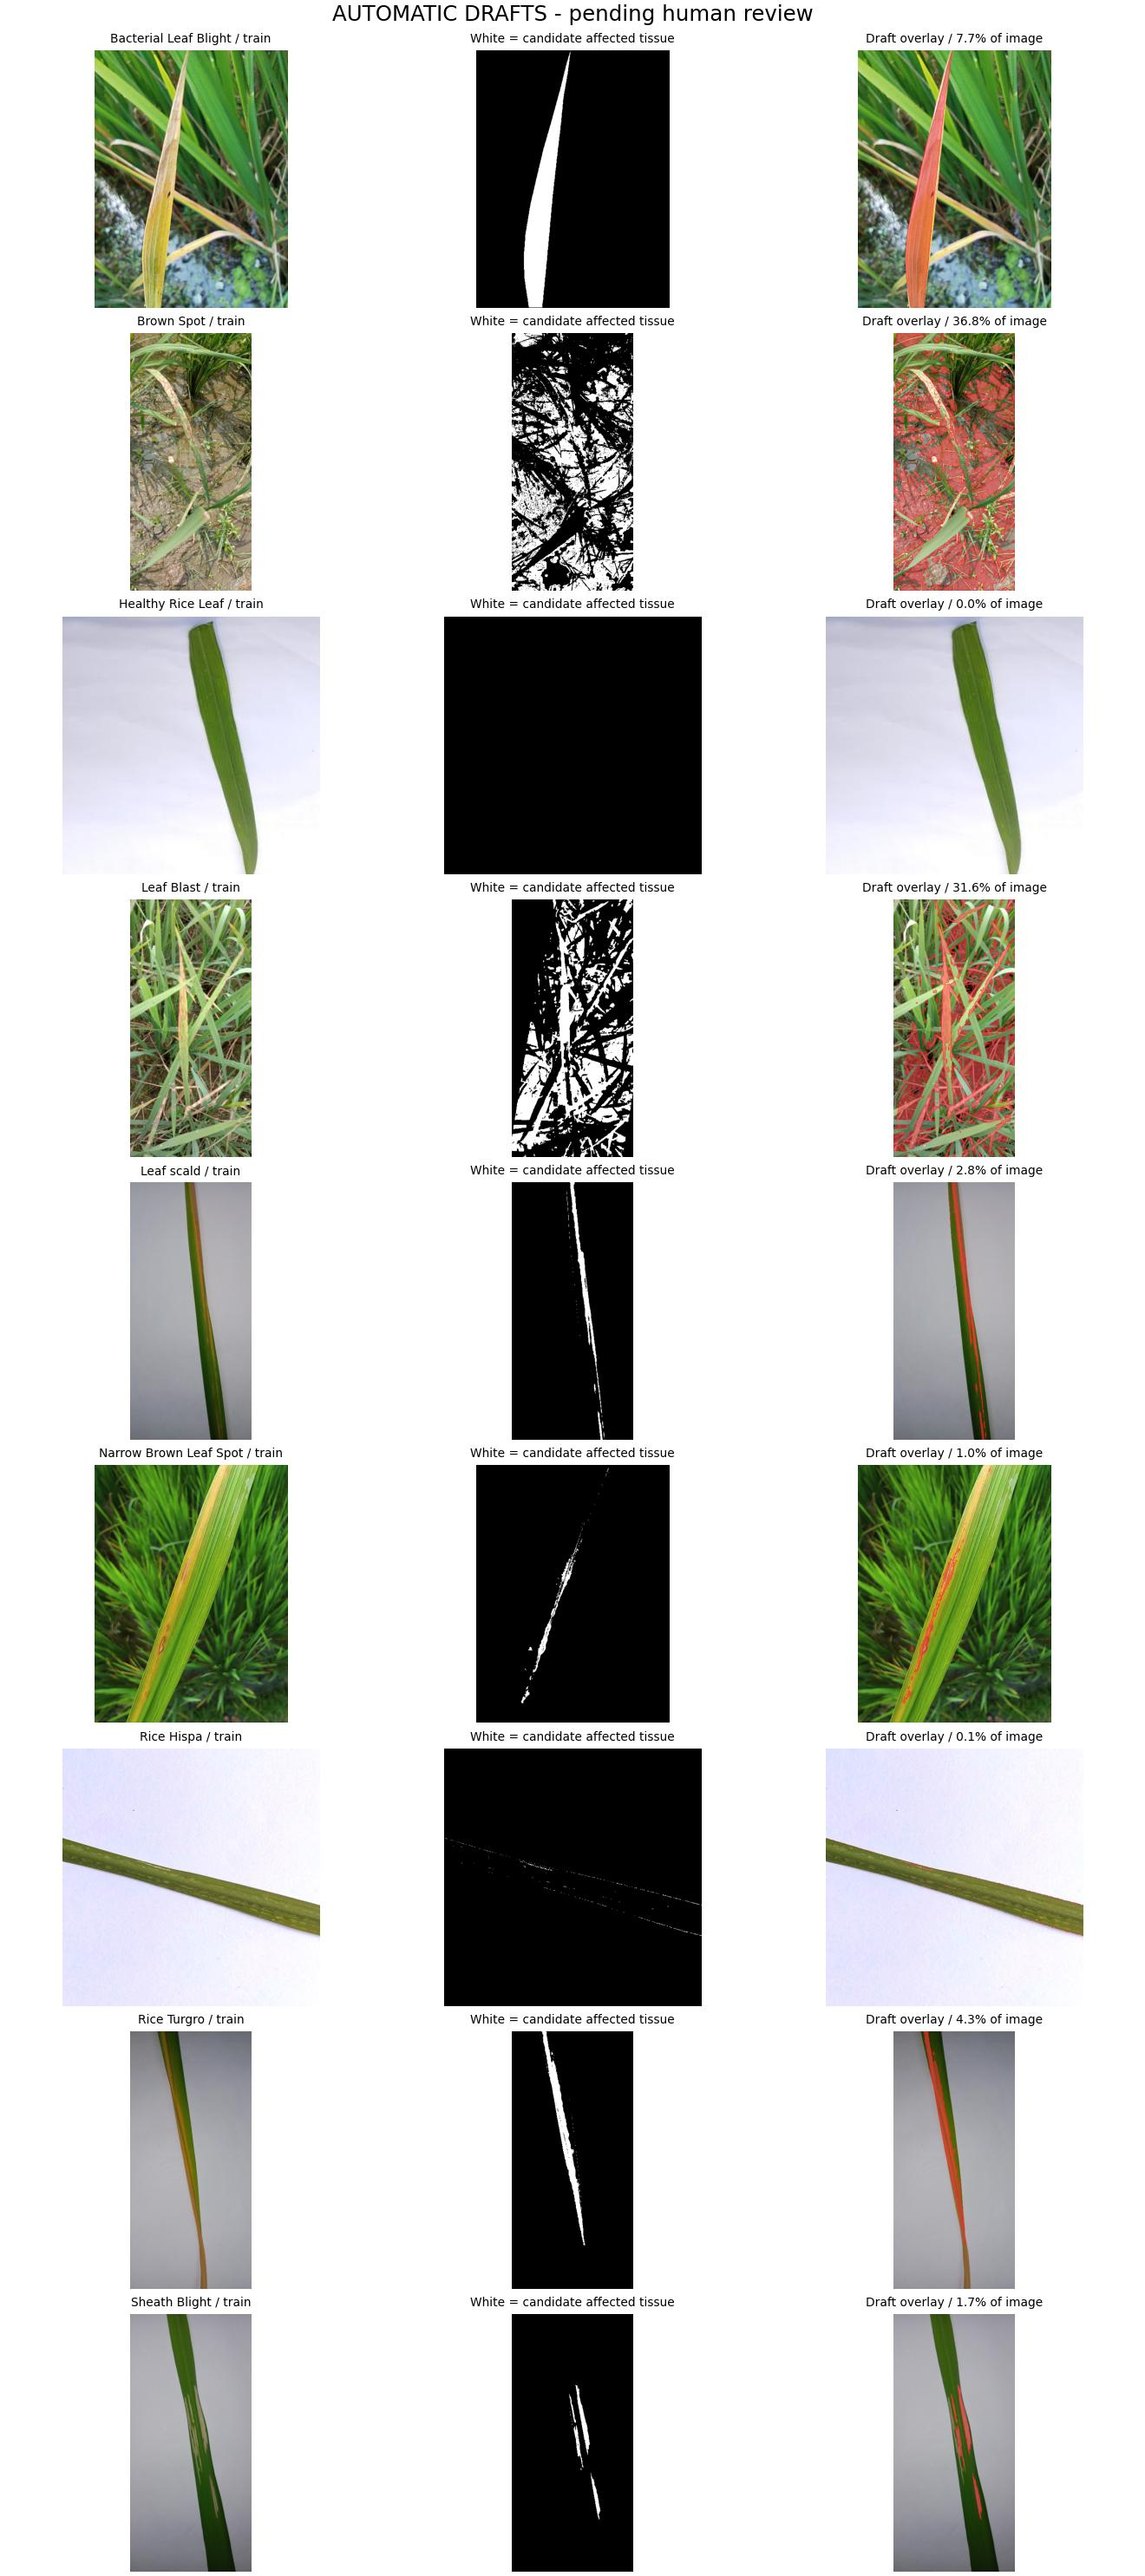

VALIDATION


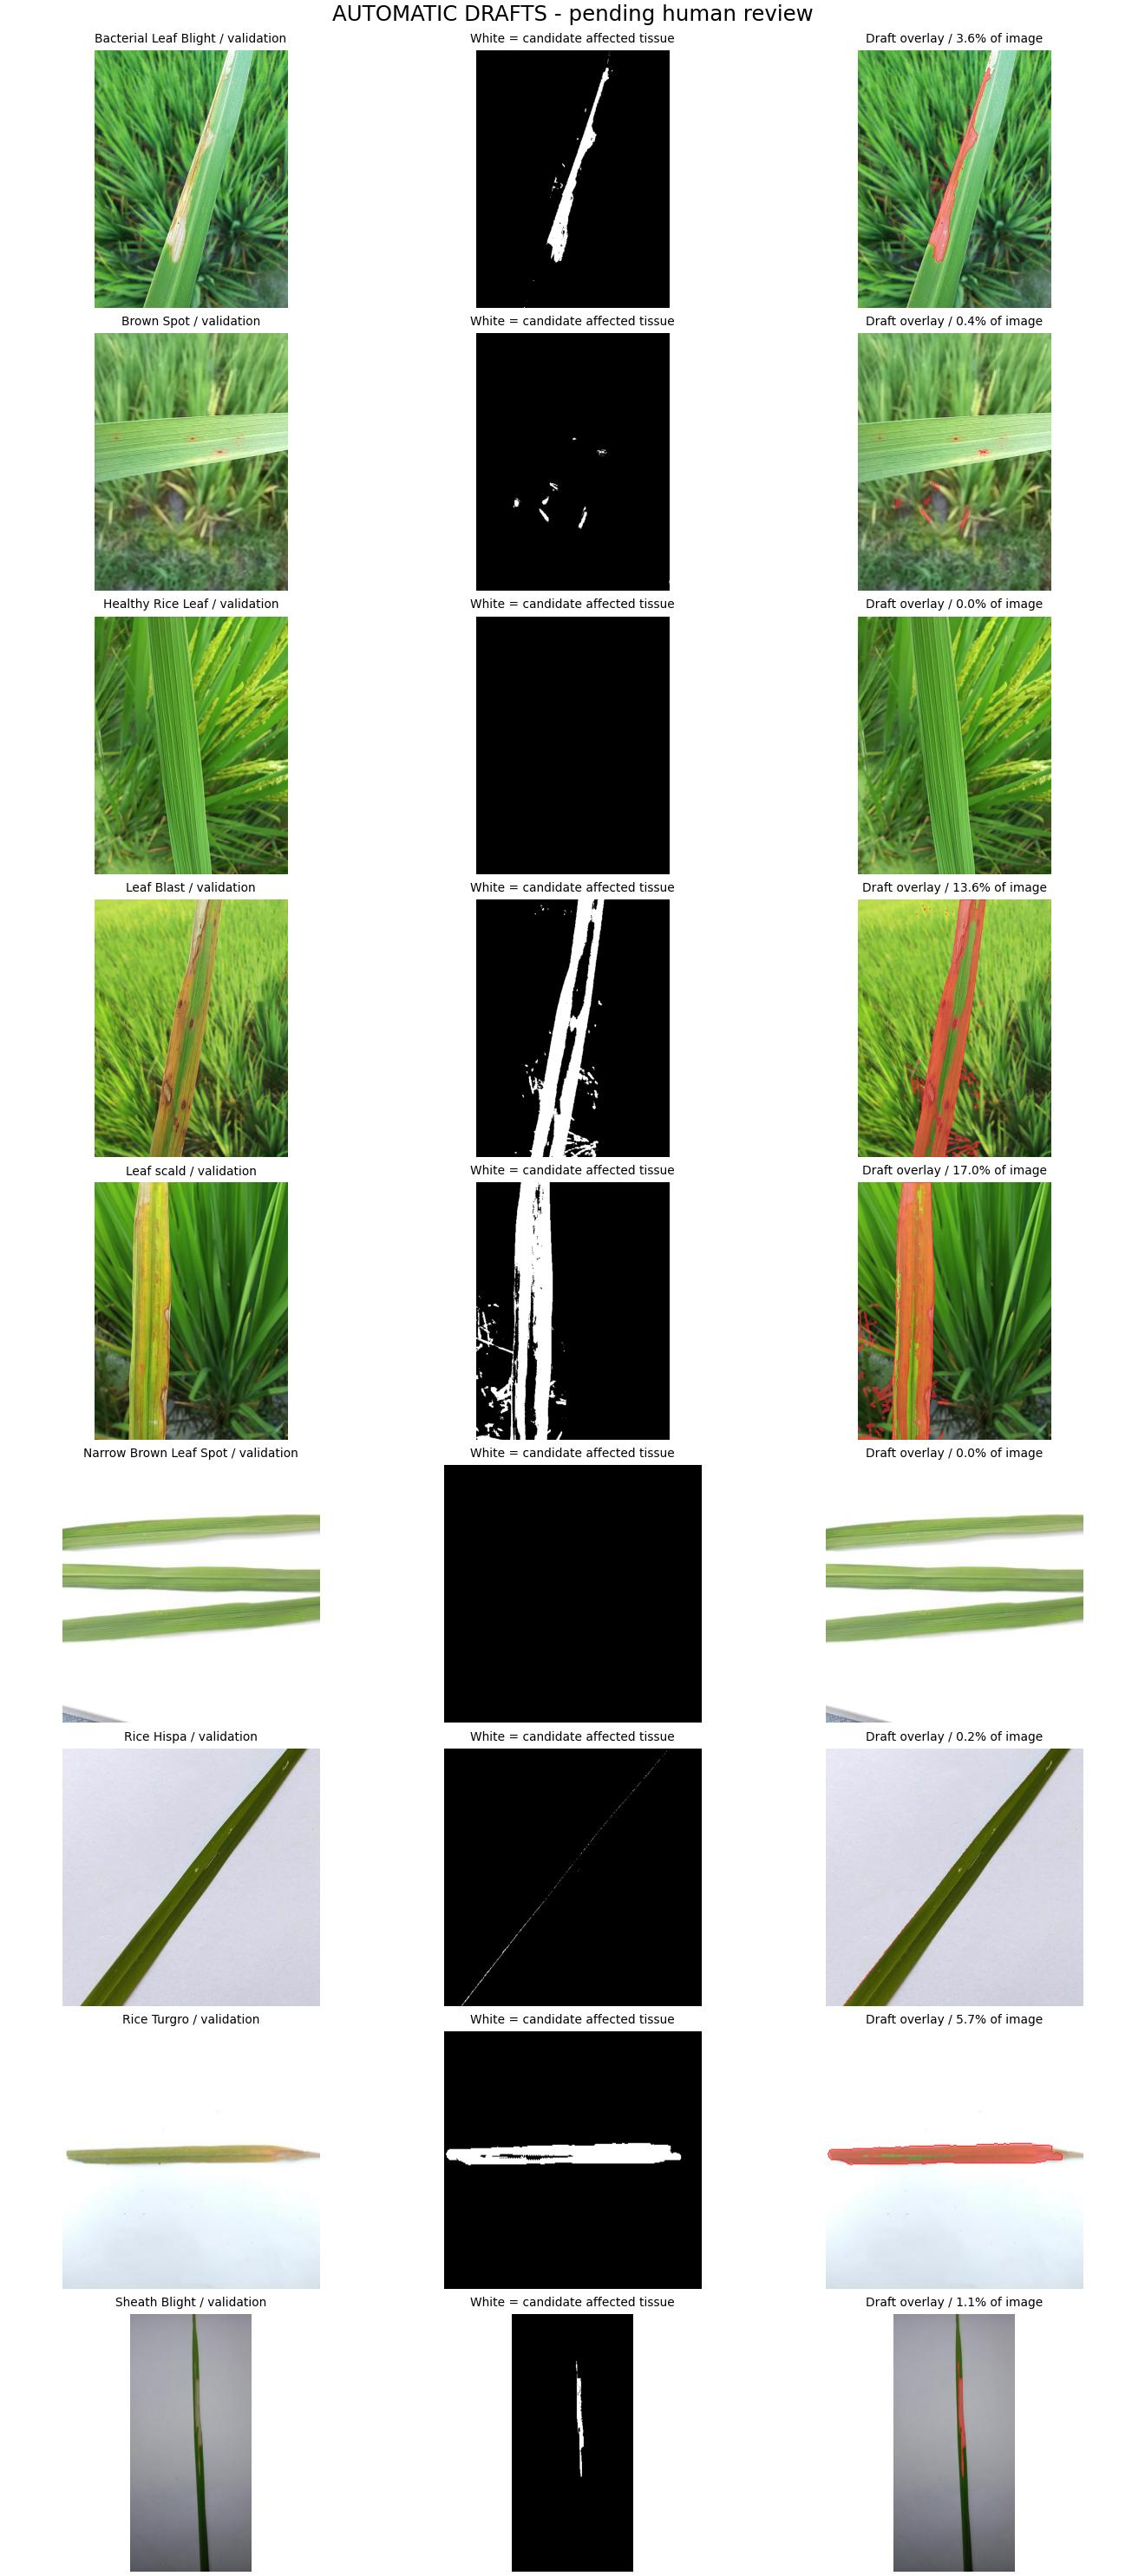

TEST


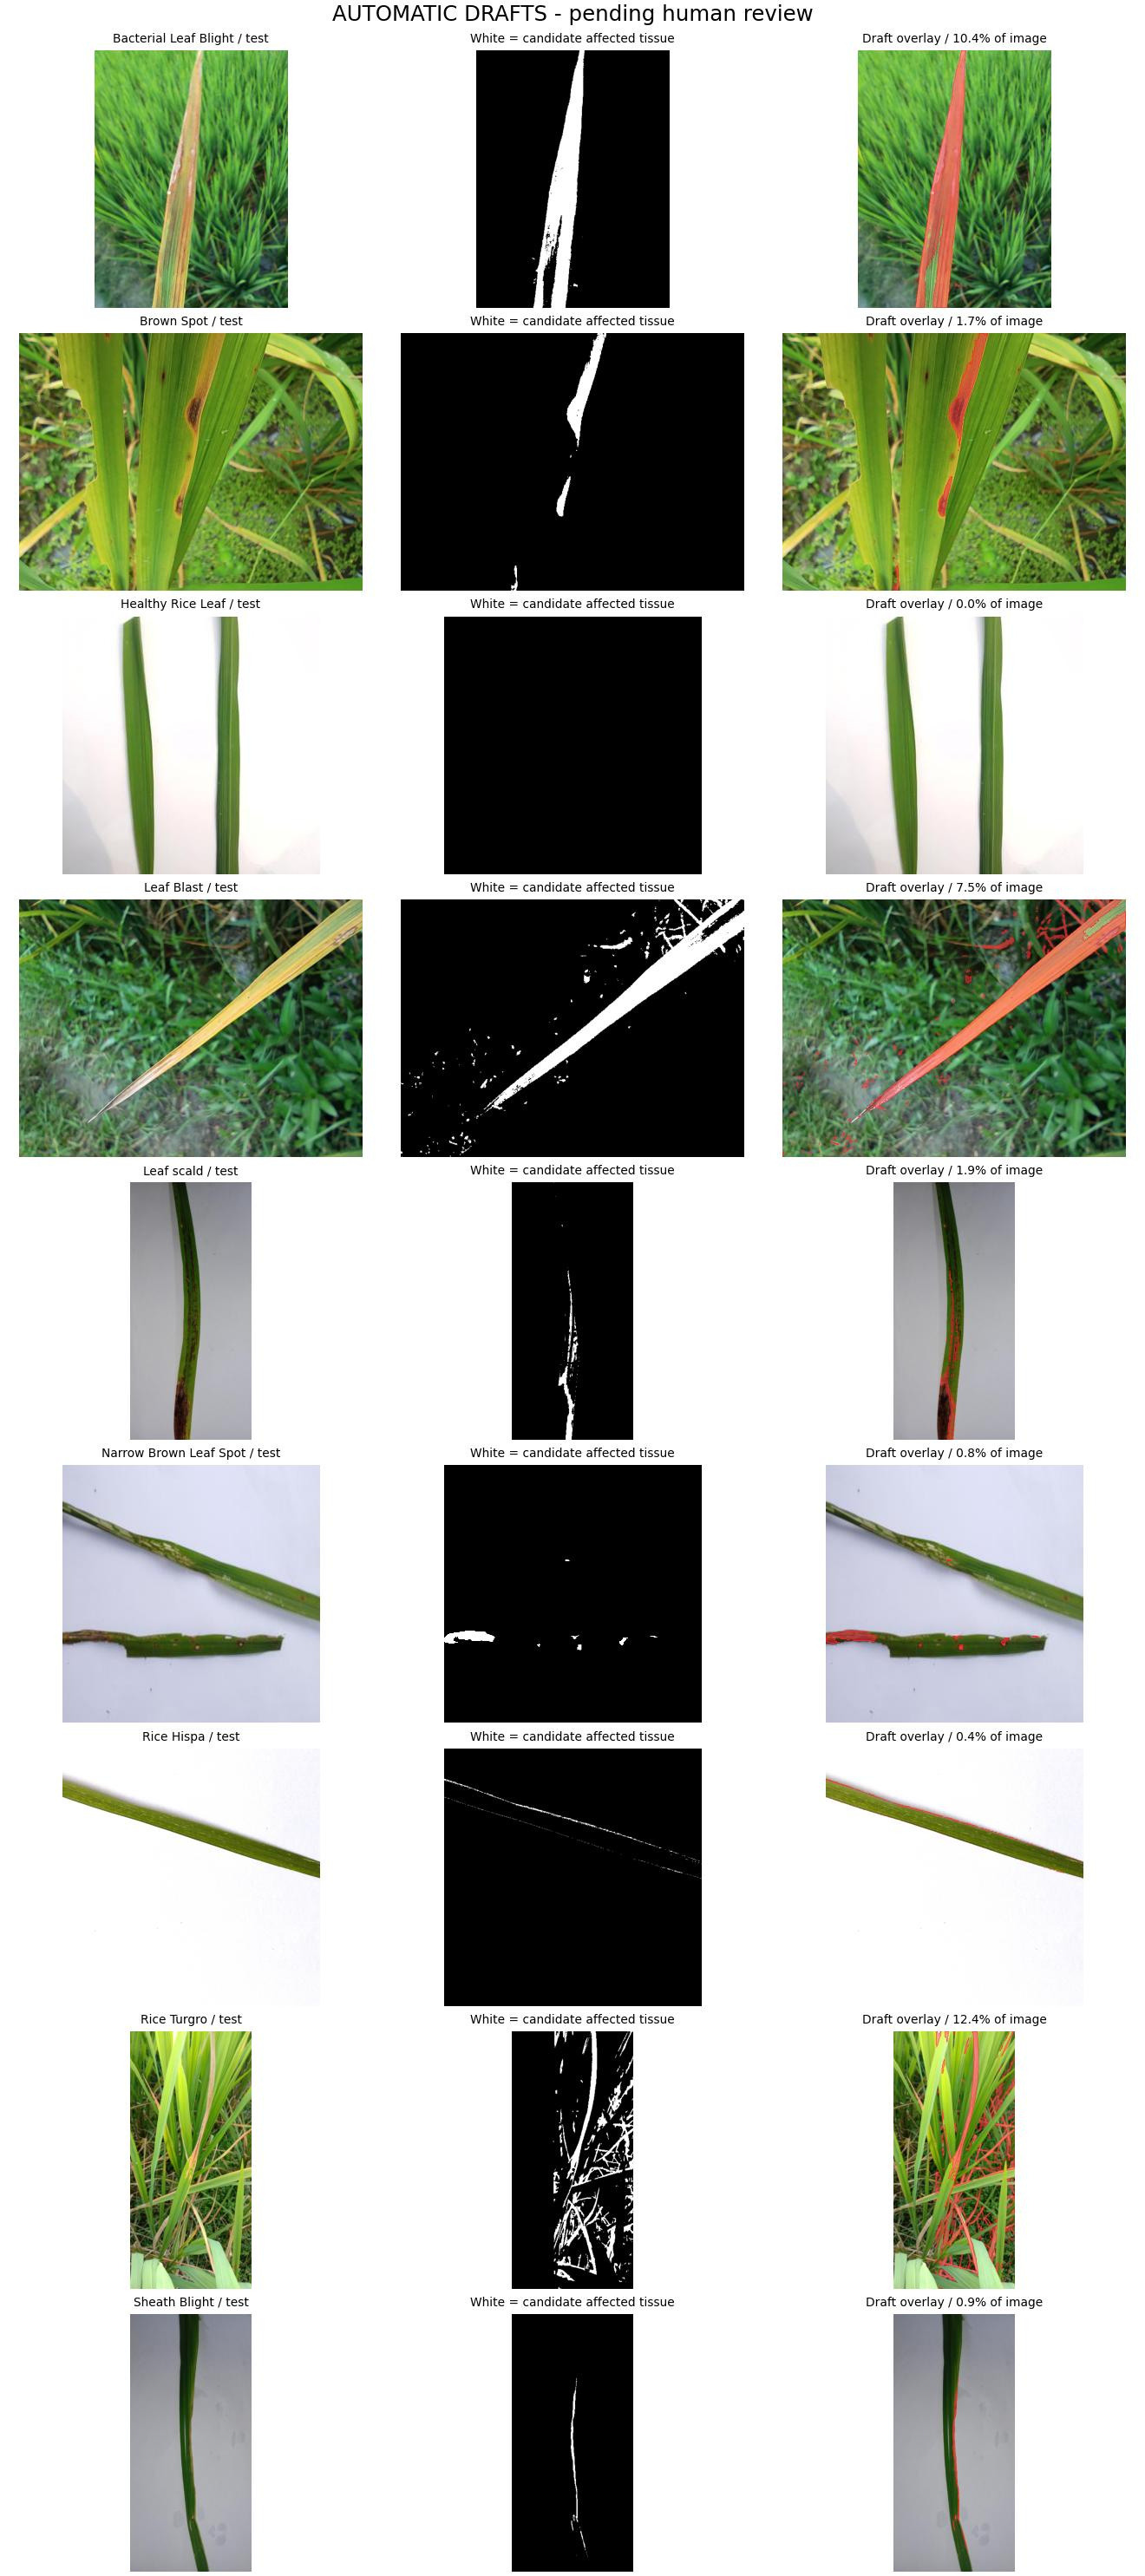

In [30]:
for split in ['train', 'validation', 'test']:
    print(split.upper())
    display(DisplayImage(filename=str(FULL_OUT / 'contact_sheets' / (split + '_examples.jpg'))))

## Full-dataset editor: preserve, add, or erase regions

Run the next cell to review all originals. The editor loads the existing automatic mask as a base. Choose **Add affected region** to include missed tissue or **Erase false region** to remove background. Click polygon vertices, close the polygon, choose a rating and decision, then save. Blue outlines indicate erasure edits until you save; saving refreshes the exact binary preview.

Uncheck **Keep automatic draft mask as the base** or choose **Clear regions** to redraw completely. Pixel-level base masks are kept intact; they are not approximated by exported contour polygons. Added regions are combined with the base first, then erasure regions are removed.

Your reviewed masks, polygons, and ratings go to `results/pixel_annotations_full/reviewed/` and `reviews/`, separately from the automatic drafts. The augmented draft masks reflect the original draft sources; future accepted corrections must be propagated with the same mask transforms before training on corrected annotations.

In [ ]:
if 'annotation_server' in globals():
    annotation_server.shutdown()
    annotation_server.server_close()
full_queue = prepare_full_dataset_queue(confirmed=True)
annotation_server, annotation_url = start_review_server(queue_path=full_queue)
print('Full-dataset editor:', annotation_url)
display(IFrame(annotation_url, width='100%', height=950))

In [31]:
display(review_table(FULL_OUT))
print('All original automatic drafts remain pending until you review them individually.')

,id,rating,decision,notes


All original automatic drafts remain pending until you review them individually.


## Augmented-mask alignment

The training source mask follows the exact geometric sequence in the dataset notebook: EXIF correction; centered fit to 256 x 256; horizontal mirror for view 1; 64-pixel reflection padding, -15 or +15 degree rotation, and crop back to 256 x 256 for views 2/3. View 4 keeps the source mask geometry because brightness/contrast do not change labels. Every mask resize and rotation uses **nearest-neighbor** sampling to preserve labels 0/1.

Validation/test originals keep their existing splits. The duplicate-removed source files are covered through their corresponding split records; the discarded duplicate images are not separately annotated.

In [32]:
checks = json.loads((FULL_OUT / 'validation.json').read_text())
print(json.dumps(checks, indent=2))
assert checks['status'] == 'passed'
assert len(original_masks) == 3893 and len(augmented_masks) == 11248
assert original_masks.mask_path.is_unique and augmented_masks.mask_path.is_unique
assert not original_masks.is_ground_truth.any()
assert not augmented_masks.is_ground_truth.any()
print('Complete coverage verified. This checks files and geometry, not biological annotation accuracy.')

{
  "original_masks": 3893,
  "augmented_masks": 11248,
  "binary_labels": true,
  "dimensions": true,
  "pixel_counts": true,
  "mask_hashes": true,
  "complete_split_coverage": true,
  "healthy_masks_empty": true,
  "status": "passed"
}
Complete coverage verified. This checks files and geometry, not biological annotation accuracy.


## Regenerate or resume exports

The command below recomputes missing originals and reuses outputs only when settings, source hashes, and mask hashes match. It then regenerates augmented draft masks and verifies all exports. Leave the switch false when you only want to inspect completed results.

In [33]:
# To regenerate all exports, run run_full_annotation() here,
# or enable REGENERATE_FULL_EXPORTS before the full-run results cell.
print('Full annotation generation is available directly as run_full_annotation().')

Full annotation generation is available directly as run_full_annotation().


## Interpretation and research use

These are **weak automatic pixel labels**, not independent expert reference masks. All ratings are blank until entered by you. Failure flags identify likely issues; absence of a flag is not proof of accuracy. Image-area percentages must not be called leaf disease severity.

Review/correct representative images from every class and background before segmentation training. Keep a separately reviewed held-out reference subset for measuring segmentation or explanation localization. Do not claim segmentation Dice/IoU or validated Grad-CAM localization performance using these draft masks as ground truth. No trained segmentation model or Grad-CAM heatmap was used to create these labels.